# Option C — Environmental sound analysis
**Mahir Foysol Chowdhury**

How does Hann window length change the visibility of a short dog bark and its frequency components? The course manifest labels `data/classification/1-100032-A-0.wav` as dog. The input is a five-second mono clip derived from [rose_bark.wav by nfrae](https://freesound.org/people/nfrae/sounds/100032/) (CC0 per the course attribution). The course manifest describes the ESC-50 package as CC BY-NC 3.0.

The analysis follows the waveform, Hann-windowed FFT and window-length comparison in Blocks 1 and 2 of `Audio_Course_Student.ipynb`. The repository includes the single source clip in `audio/`. Attribution is listed in the README.

In [1]:
from pathlib import Path
from math import gcd
from IPython.display import Audio, display

import matplotlib.pyplot as plt
import numpy as np
from scipy import signal
from scipy.io import wavfile

CLIP = Path('audio/1-100032-A-0.wav')
FS = 16_000
HOP = 160
RESULTS = Path('results')
RESULTS.mkdir(exist_ok=True)

original_rate, raw = wavfile.read(CLIP)
assert raw.dtype == np.int16 and raw.ndim == 1
factor = gcd(original_rate, FS)
audio = signal.resample_poly(raw.astype(float) / 32768, FS // factor, original_rate // factor)
time = np.arange(audio.size) / FS
print(f'{CLIP}: {original_rate} Hz original, {FS} Hz analysis, mono, {audio.size / FS:.2f} s')


audio/1-100032-A-0.wav: 44100 Hz original, 16000 Hz analysis, mono, 5.00 s


## Waveform and spectrum
The waveform locates the event in time. The spectrum follows the lecture method by subtracting the mean, multiplying by a Hann window and expressing FFT magnitude relative to its peak. The shaded area marks the event for closer inspection.

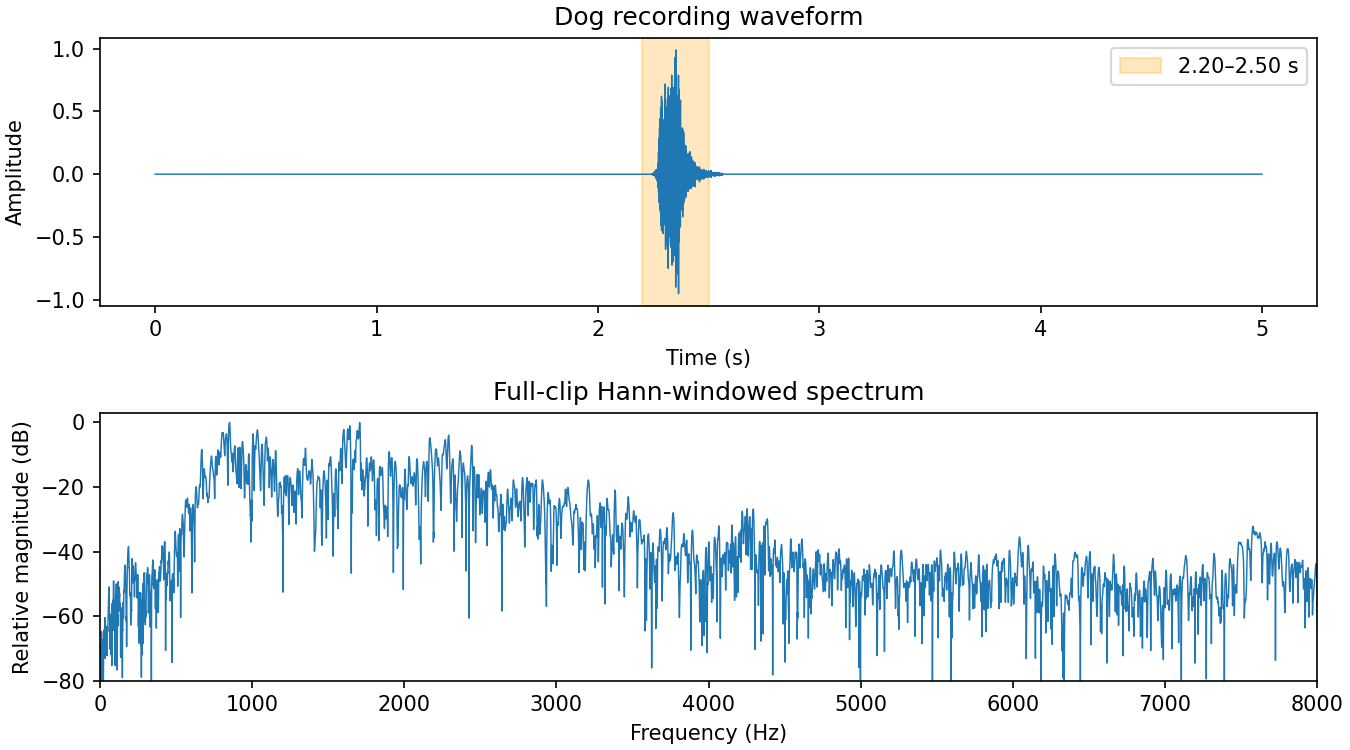

In [2]:
start, stop = 2.2, 2.5
freq = np.fft.rfftfreq(audio.size, 1 / FS)
mag = np.abs(np.fft.rfft((audio - audio.mean()) * np.hanning(audio.size)))
db = 20 * np.log10(np.maximum(mag / mag.max(), 1e-6))

fig, axes = plt.subplots(2, 1, figsize=(9, 5), layout='constrained')
axes[0].plot(time, audio, linewidth=0.7)
axes[0].axvspan(start, stop, color='orange', alpha=0.25, label='2.20–2.50 s')
axes[0].set(xlabel='Time (s)', ylabel='Amplitude', title='Dog recording waveform')
axes[0].legend()
axes[1].plot(freq, db, linewidth=0.7)
axes[1].set(xlabel='Frequency (Hz)', ylabel='Relative magnitude (dB)',
            title='Full-clip Hann-windowed spectrum', xlim=(0, 8000), ylim=(-80, 3))
fig.savefig(RESULTS / 'waveform_spectrum.png', dpi=150)
plt.show()


## Spectrogram comparison
Both spectra use the same 16 kHz signal, Hann window family, 160-sample hop (10 ms), axis limits and power-density reference. Plotting the same time interval around the event makes differences easier to see.

512 samples: 32 ms, 31.25 Hz bin spacing
2048 samples: 128 ms, 7.812 Hz bin spacing
2.20 s segment starts: strongest bin 800 Hz
2.30 s segment starts: strongest bin 1700 Hz
2.40 s segment starts: strongest bin 1710 Hz


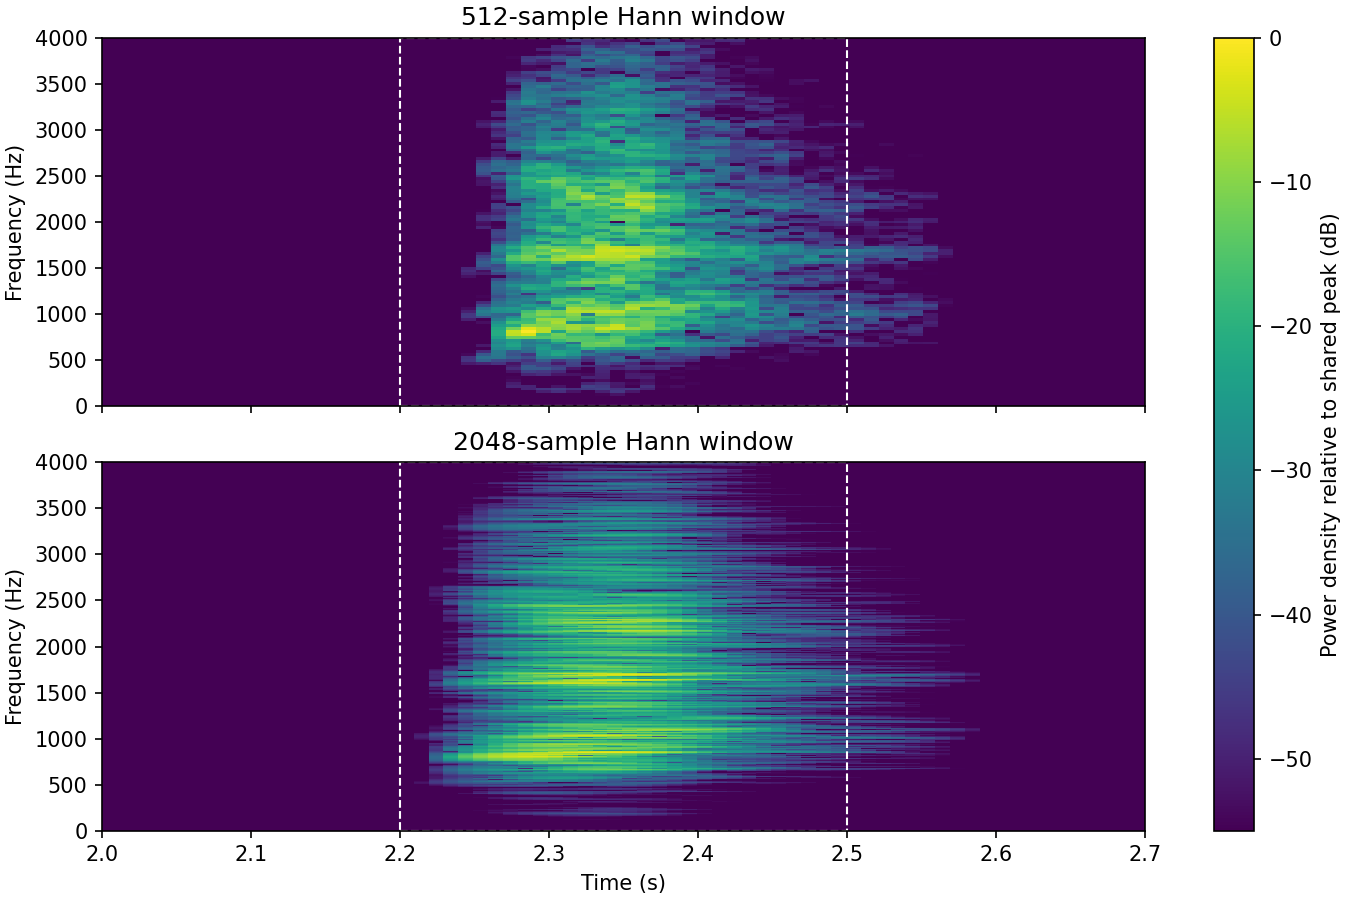

In [3]:
windows = (512, 2048)
spectra = []
for length in windows:
    f, t, power = signal.spectrogram(
        audio, fs=FS, window='hann', nperseg=length, noverlap=length-HOP,
        nfft=length, detrend=False, scaling='density'
    )
    spectra.append((length, f, t, power))
    print(f'{length} samples: {1000 * length / FS:.0f} ms, {FS / length:.4g} Hz bin spacing')

reference = max(power.max() for _, _, _, power in spectra)
fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True, sharey=True, layout='constrained')
for ax, (length, f, t, power) in zip(axes, spectra):
    db = 10 * np.log10(np.maximum(power / reference, 1e-12))
    image = ax.pcolormesh(t, f, db, shading='nearest', vmin=-55, vmax=0)
    ax.axvspan(start, stop, facecolor='none', edgecolor='white', linestyle='--')
    ax.set(title=f'{length}-sample Hann window', ylabel='Frequency (Hz)',
           xlim=(2.0, 2.7), ylim=(0, 4000))
axes[-1].set_xlabel('Time (s)')
fig.colorbar(image, ax=axes, label='Power density relative to shared peak (dB)')
fig.savefig(RESULTS / 'spectrograms.png', dpi=150)
plt.show()

event = audio[round(start * FS):round(stop * FS)]
segments = event.reshape(3, FS // 10)
freq, power = signal.periodogram(segments, FS, window='hann', axis=-1)
for index, row in enumerate(power):
    print(f'{start + index / 10:.2f} s segment starts: strongest bin {freq[row.argmax()]:.0f} Hz')


## Interpretation
The strongest waveform activity falls around **2.20–2.50 s**. A relevant frequency region is **0.8–1.8 kHz**. As a numerical check, the strongest periodogram bin moves from about 800 Hz in the first 100 ms segment to about 1.7 kHz in the next two segments. The 512-sample window covers 32 ms and localizes the rapid changes more closely. The 2048-sample window covers 128 ms and shows narrower frequency structure while smearing changes over time. The 10 ms hop is the same in both cases, so only the window and associated FFT length change.

**Limitation.** The experiment uses one ESC-50 clip. The timing and frequency peaks describe this clip and can depend on the dog, microphone and recording conditions.

**Listening observation.** I heard a short dog bark that sounded like “bau.” It matches the burst of energy around 2.20–2.50 s in the waveform and spectrograms.

In [4]:
display(Audio(filename=str(CLIP)))

Dog recording playback